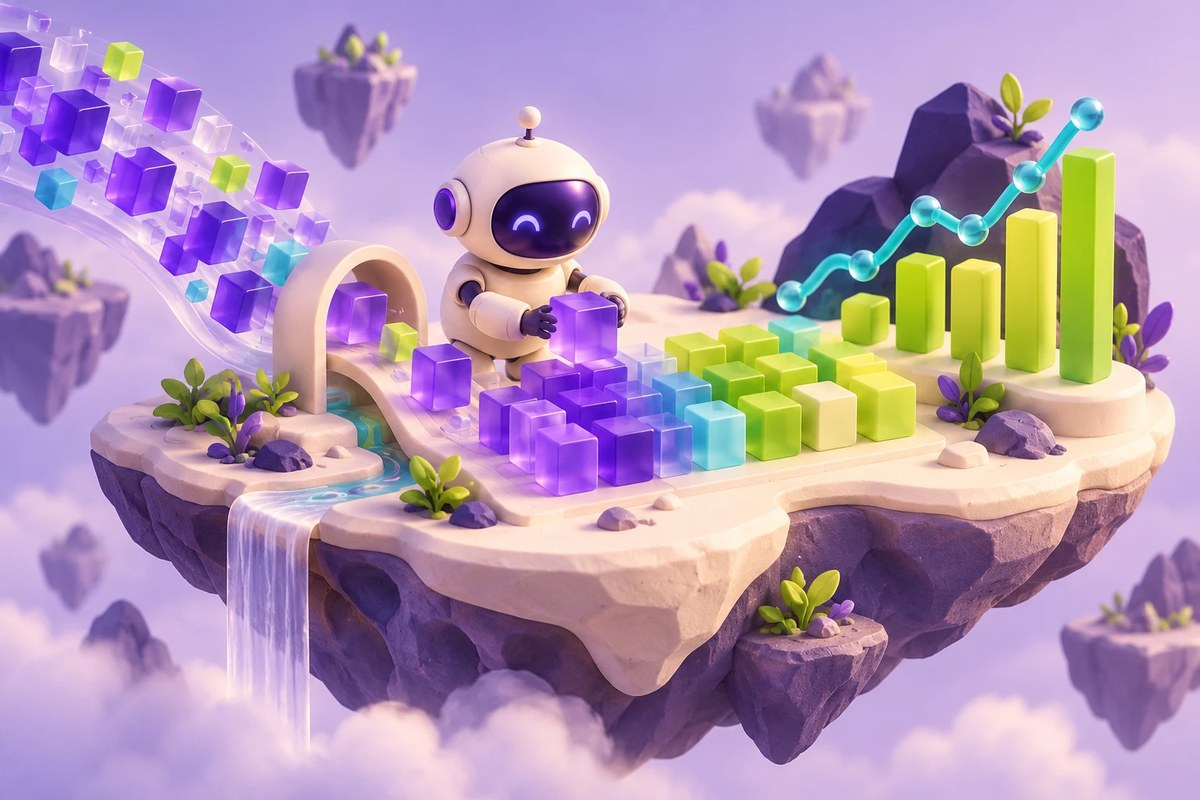

AI PATH · Python для машинного обучения · Урок 065

# Seaborn: три способа увидеть данные

Регрессия, многомерное облако точек и сравнительные гистограммы

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-065-goal"></a>
## Что вы разберёте

Выбрать визуальную форму под вопрос и объяснить, какие переменные кодируются положением, цветом, размером и отдельными панелями.

### Перед началом

- Таблица с числовыми и категориальными столбцами
- Основы Python и построения графиков

### Что понадобится

- Seaborn, Matplotlib и NumPy
- Доступ к учебным наборам anscombe, diamonds и tips через sns.load_dataset() либо их локальному кэшу

## Навигация по уроку

- [Цель и подготовка](#ai-065-goal)
- [Карта урока](#ai-065-map)
- [Смотрим на форму, а не только на линию](#ai-065-section-01)
- [Добавляем визуальные каналы](#ai-065-section-02)
- [Сравниваем распределения](#ai-065-section-03)
- [Проверьте понимание](#ai-065-practice)
- [Источники и ограничения](#ai-065-provenance)

<a id="ai-065-map"></a>
## Карта урока

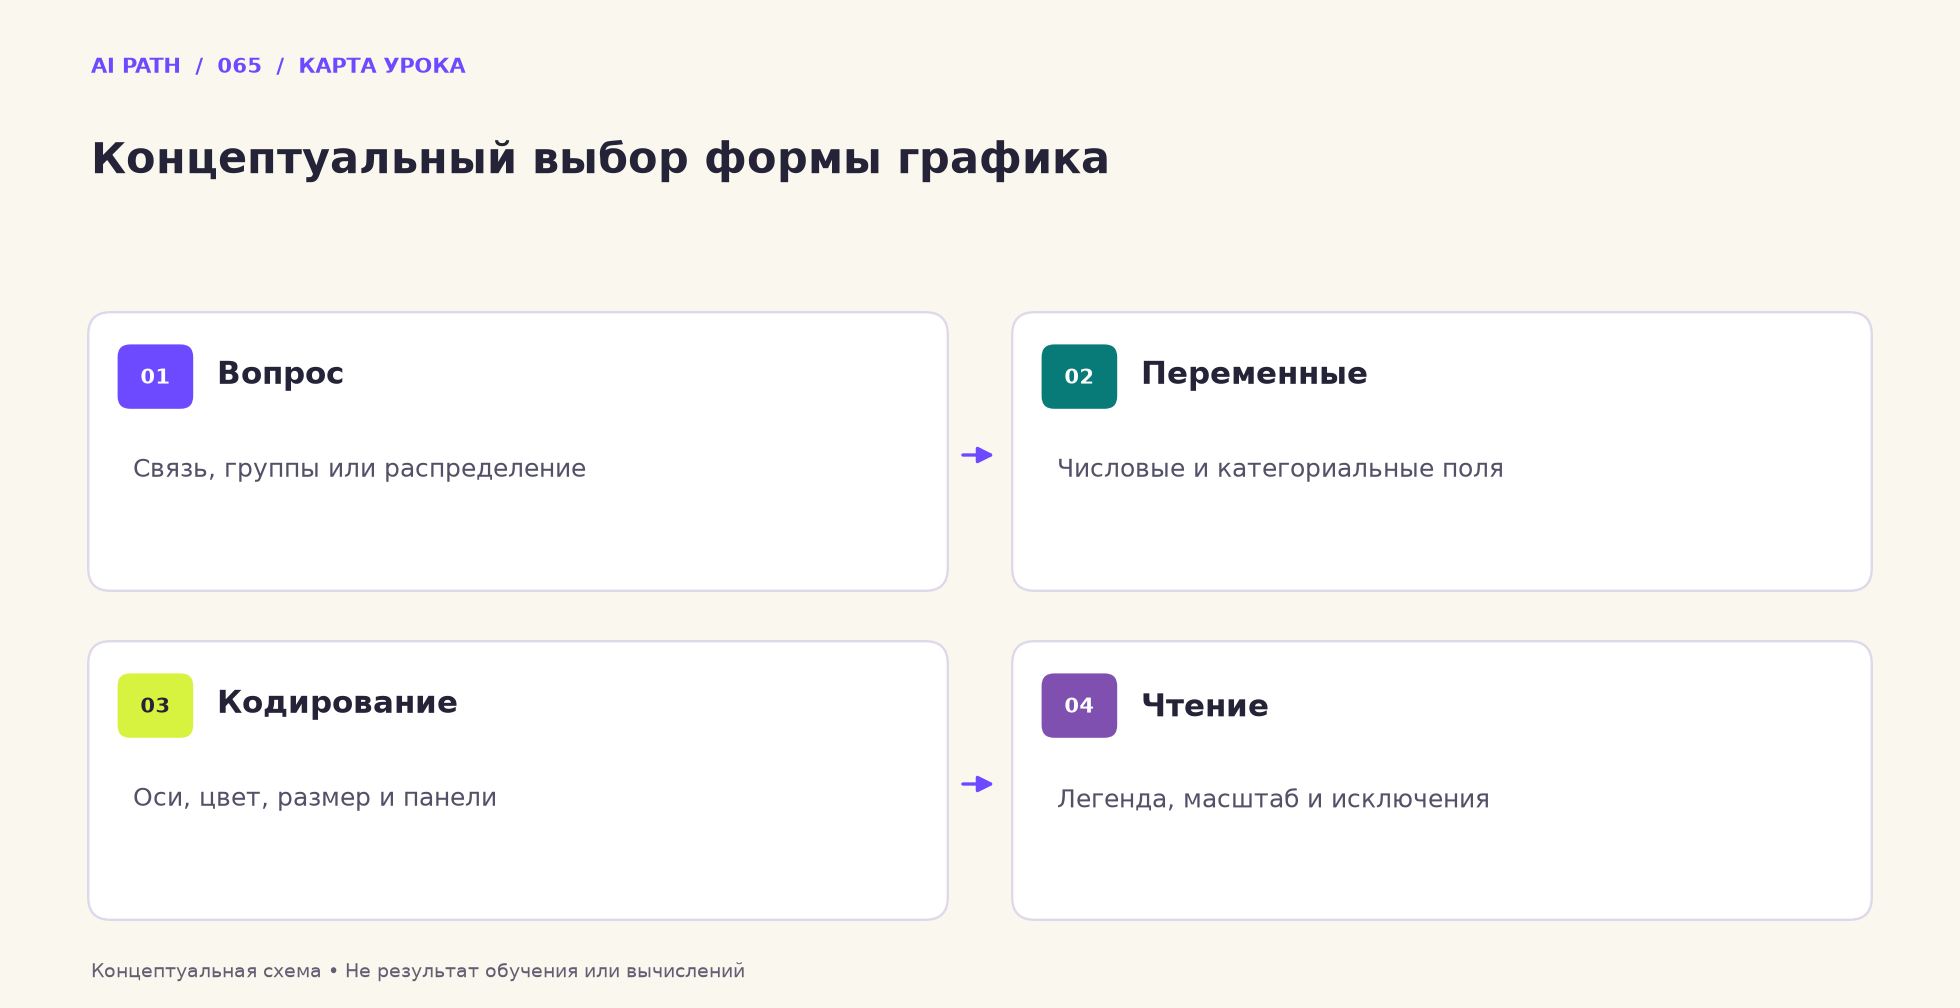

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Вопрос** — Связь, группы или распределение
2. **Переменные** — Числовые и категориальные поля
3. **Кодирование** — Оси, цвет, размер и панели
4. **Чтение** — Легенда, масштаб и исключения

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/seaborn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="ai-065-section-01"></a>
## 01 · Смотрим на форму, а не только на линию

Четыре набора Anscombe отображаются отдельно с линейной регрессией. Рассмотрите облака точек и выбросы до интерпретации общего тренда.

_Далее — исходные ячейки учебного материала._

/usr/local/lib/python3.6/dist-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


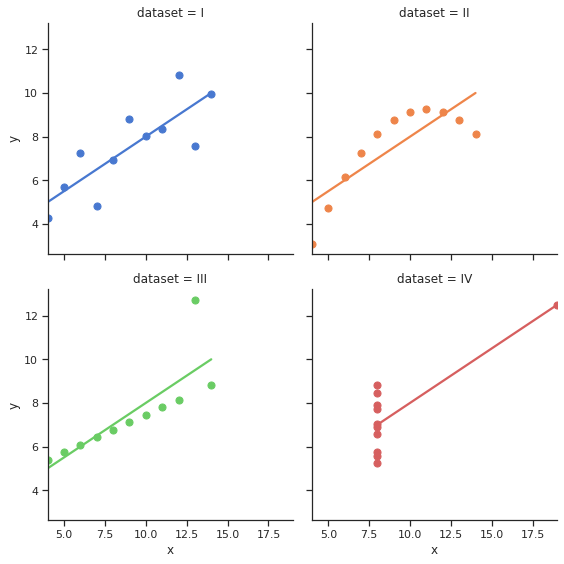

In [1]:
import seaborn as sns
sns.set(style="ticks")

# Load the example dataset for Anscombe's quartet
df = sns.load_dataset("anscombe")

# Show the results of a linear regression within each dataset
sns.lmplot(x="x", y="y", col="dataset", hue="dataset", data=df,
           col_wrap=2, ci=None, palette="muted", height=4,
           scatter_kws={"s": 50, "alpha": 1})

<a id="ai-065-section-02"></a>
## 02 · Добавляем визуальные каналы

В diamonds положение показывает carat и price, цвет — clarity, размер — depth. Прочитайте легенду и оцените, различимы ли очень маленькие точки.

_Далее — исходные ячейки учебного материала._

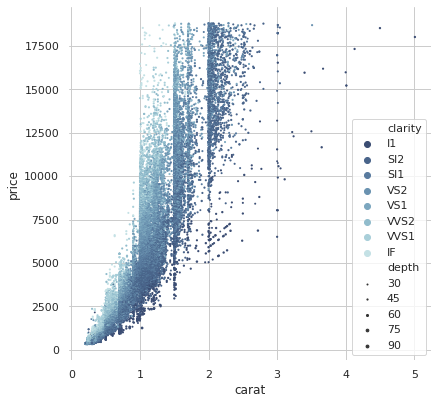

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(style="whitegrid")

# Load the example diamonds dataset
diamonds = sns.load_dataset("diamonds")

# Draw a scatter plot while assigning point colors and sizes to different
# variables in the dataset
f, ax = plt.subplots(figsize=(6.5, 6.5))
sns.despine(f, left=True, bottom=True)
clarity_ranking = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]
sns.scatterplot(x="carat", y="price",
                hue="clarity", size="depth",
                palette="ch:r=-.2,d=.3_r",
                hue_order=clarity_ranking,
                sizes=(1, 8), linewidth=0,
                data=diamonds, ax=ax)

<a id="ai-065-section-03"></a>
## 03 · Сравниваем распределения

FacetGrid разделяет tips по sex и time; единые интервалы гистограммы помогают сопоставлять форму распределений, но количество наблюдений в группах может различаться.

_Далее — исходные ячейки учебного материала._

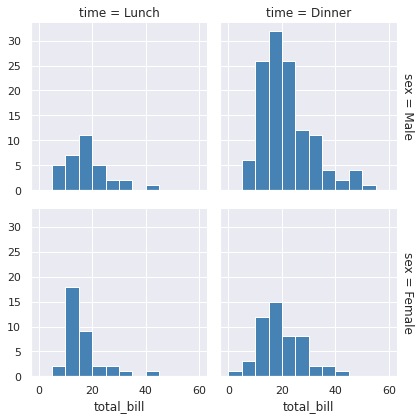

In [4]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(style="darkgrid")

tips = sns.load_dataset("tips")
g = sns.FacetGrid(tips, row="sex", col="time", margin_titles=True)
bins = np.linspace(0, 60, 13)
g.map(plt.hist, "total_bill", color="steelblue", bins=bins)

<a id="ai-065-practice"></a>
## Проверьте понимание

1. Что скрыла бы одна линия регрессии без точек в квартете Anscombe?
2. Какие четыре поля diamonds закодированы в одном scatterplot?
3. Почему одинаковые bins помогают сравнению гистограмм, но не выравнивают размеры групп?

### Один самостоятельный эксперимент

Для diamonds сравните исходные размеры точек (1, 8) с более читаемым диапазоном, затем проверьте легенду и перекрытие на плотных участках.

**Критерий успеха:** Значения данных не изменены, кодирование depth объяснимо, а различия категорий и плотные области видны без ложного усиления отдельных наблюдений.

<a id="ai-065-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/seaborn/seaborn.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- sns.load_dataset может обращаться к сети; наличие локального кэша не проверено.
- Наборы являются учебными и не описывают текущие цены или поведение людей.
- Графики повторно не строились; визуальную читаемость необходимо проверить в реальном размере вывода.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.